In [1]:
import pandas as pd
from functools import reduce
import numpy as np

In [2]:
#Wczytanie danych
CDR=pd.read_csv("Dane/cdr_d.csv")
CDR["Data"] = pd.to_datetime(CDR["Data"])
CDR = CDR.sort_values("Data")
CDR = CDR[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_CDR"})

CDR = CDR.sort_values("Data").reset_index(drop=True)
CDR = CDR[(CDR["Data"] >= "2015-01-01") & (CDR["Data"] <= "2019-12-31")]
CDR = CDR.reset_index(drop=True)

CDR

,Data,Close_CDR
0,2015-01-02,15.5614
1,2015-01-05,15.3952
2,2015-01-07,15.5983
3,2015-01-08,15.5799
4,2015-01-09,15.6081
...,...,...
1242,2019-12-19,253.7350
1243,2019-12-20,255.0560
1244,2019-12-23,264.4020
1245,2019-12-27,262.2270


In [3]:
CDR['Log_Return'] = np.log(CDR['Close_CDR'] / CDR['Close_CDR'].shift(1))

CDR

,Data,Close_CDR,Log_Return
0,2015-01-02,15.5614,NaN
1,2015-01-05,15.3952,-0.010738
2,2015-01-07,15.5983,0.013106
3,2015-01-08,15.5799,-0.001180
4,2015-01-09,15.6081,0.001808
...,...,...,...
1242,2019-12-19,253.7350,0.002261
1243,2019-12-20,255.0560,0.005193
1244,2019-12-23,264.4020,0.035988
1245,2019-12-27,262.2270,-0.008260


In [4]:
CDR['Close_CDR'].describe()

count    1247.000000
mean       95.193577
std        73.119787
min        14.682200
25%        24.638100
50%        77.533100
75%       155.488000
max       264.402000
Name: Close_CDR, dtype: float64

In [5]:
CDR['Log_Return'].describe()

count    1246.000000
mean        0.002272
std         0.024146
min        -0.111271
25%        -0.010276
50%         0.001005
75%         0.015086
max         0.186279
Name: Log_Return, dtype: float64

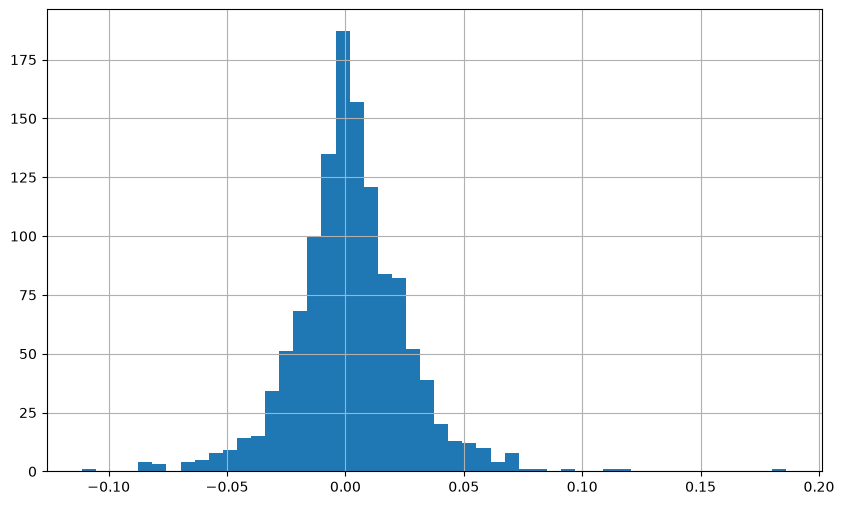

In [6]:
hist_CDR = CDR['Log_Return'].hist(bins=50, figsize=(10, 6))